# Carbon Footprint Prediction

### Problem Statement
Can we predict a person's carbon emission from their lifestyle habits, and which habits contribute the most?

### Objectives
- Explore and clean the data (duplicates, missing values, data types)
- Understand the distribution of the target variable, CarbonEmission
- Identify the key drivers of emissions among numeric and categorical features
- Prepare the features for regression (encoding, splitting list-type columns)
- Build and evaluate a linear regression model (R², MAE, RMSE)
- Interpret the model's coefficients to explain which choices raise or lower emissions

##### Goal: Predict CarbonEmission of an individual based on multiple behavioral and lifestyle attributes.


### Dataset Overview
The dataset contains **10000 rows** and **20 columns**. Target variable: **CarbonEmission**.

### Importing Libraries

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

### Load the dataset

In [2]:
df = pd.read_csv(r"C:\Users\tanis\Carbon Emission - LMS.csv")

In [3]:
df

,Body Type,Sex,Diet,How Often Shower,Heating Energy Source,Transport,Vehicle Type,Social Activity,Monthly Grocery Bill,Frequency of Traveling by Air,Vehicle Monthly Distance Km,Waste Bag Size,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,Energy efficiency,Recycling,Cooking_With,CarbonEmission
0,overweight,female,pescatarian,daily,coal,public,NaN,often,230,frequently,210,large,4,7,26,1,No,['Metal'],"['Stove', 'Oven']",2238
1,obese,female,vegetarian,less frequently,natural gas,walk/bicycle,NaN,often,114,rarely,9,extra large,3,9,38,5,No,['Metal'],"['Stove', 'Microwave']",1892
2,overweight,male,omnivore,more frequently,wood,private,petrol,never,138,never,2472,small,1,14,47,6,Sometimes,['Metal'],"['Oven', 'Microwave']",2595
3,overweight,male,omnivore,twice a day,wood,walk/bicycle,NaN,sometimes,157,rarely,74,medium,3,20,5,7,Sometimes,"['Paper', 'Plastic', 'Glass', 'Metal']","['Microwave', 'Grill', 'Airfryer']",1074
4,obese,female,vegetarian,daily,coal,private,diesel,often,266,very frequently,8457,large,1,3,5,6,Yes,['Paper'],['Oven'],4743
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,obese,male,omnivore,twice a day,coal,private,hybrid,sometimes,230,never,268,medium,5,12,27,9,Yes,[],['Microwave'],2408
9996,normal,female,vegan,twice a day,coal,private,lpg,never,234,frequently,5316,extra large,3,14,8,24,Sometimes,"['Paper', 'Plastic']","['Stove', 'Microwave']",3084
9997,overweight,female,vegetarian,daily,electricity,walk/bicycle,NaN,sometimes,298,very frequently,96,extra large,5,11,5,24,Yes,"['Paper', 'Plastic', 'Metal']","['Microwave', 'Grill', 'Airfryer']",2377
9998,underweight,male,vegan,more frequently,coal,private,petrol,often,179,rarely,8688,medium,5,19,14,5,Sometimes,"['Paper', 'Metal']","['Stove', 'Microwave', 'Grill', 'Airfryer']",4574


### Initial Dataset Overview

### Before any cleaning, let's look at the raw shape, structure, and a preview of the data.

In [4]:
df.head()     # displays the top 5 rows

,Body Type,Sex,Diet,How Often Shower,Heating Energy Source,Transport,Vehicle Type,Social Activity,Monthly Grocery Bill,Frequency of Traveling by Air,Vehicle Monthly Distance Km,Waste Bag Size,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,Energy efficiency,Recycling,Cooking_With,CarbonEmission
0,overweight,female,pescatarian,daily,coal,public,NaN,often,230,frequently,210,large,4,7,26,1,No,['Metal'],"['Stove', 'Oven']",2238
1,obese,female,vegetarian,less frequently,natural gas,walk/bicycle,NaN,often,114,rarely,9,extra large,3,9,38,5,No,['Metal'],"['Stove', 'Microwave']",1892
2,overweight,male,omnivore,more frequently,wood,private,petrol,never,138,never,2472,small,1,14,47,6,Sometimes,['Metal'],"['Oven', 'Microwave']",2595
3,overweight,male,omnivore,twice a day,wood,walk/bicycle,NaN,sometimes,157,rarely,74,medium,3,20,5,7,Sometimes,"['Paper', 'Plastic', 'Glass', 'Metal']","['Microwave', 'Grill', 'Airfryer']",1074
4,obese,female,vegetarian,daily,coal,private,diesel,often,266,very frequently,8457,large,1,3,5,6,Yes,['Paper'],['Oven'],4743


In [5]:
df.tail()     # displays the last 5 rows

,Body Type,Sex,Diet,How Often Shower,Heating Energy Source,Transport,Vehicle Type,Social Activity,Monthly Grocery Bill,Frequency of Traveling by Air,Vehicle Monthly Distance Km,Waste Bag Size,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,Energy efficiency,Recycling,Cooking_With,CarbonEmission
9995,obese,male,omnivore,twice a day,coal,private,hybrid,sometimes,230,never,268,medium,5,12,27,9,Yes,[],['Microwave'],2408
9996,normal,female,vegan,twice a day,coal,private,lpg,never,234,frequently,5316,extra large,3,14,8,24,Sometimes,"['Paper', 'Plastic']","['Stove', 'Microwave']",3084
9997,overweight,female,vegetarian,daily,electricity,walk/bicycle,NaN,sometimes,298,very frequently,96,extra large,5,11,5,24,Yes,"['Paper', 'Plastic', 'Metal']","['Microwave', 'Grill', 'Airfryer']",2377
9998,underweight,male,vegan,more frequently,coal,private,petrol,often,179,rarely,8688,medium,5,19,14,5,Sometimes,"['Paper', 'Metal']","['Stove', 'Microwave', 'Grill', 'Airfryer']",4574
9999,obese,male,pescatarian,twice a day,wood,private,electric,sometimes,115,never,9952,small,4,11,6,0,Sometimes,"['Plastic', 'Glass', 'Metal']","['Oven', 'Grill', 'Airfryer']",826


In [6]:
df.shape    #(rows,columns)

(10000, 20)

In [7]:
df.describe()

,Monthly Grocery Bill,Vehicle Monthly Distance Km,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,CarbonEmission
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,173.875200,2031.485900,4.024600,12.139200,25.109000,11.889100,2269.147300
std,72.234018,2769.715597,1.990375,7.106369,14.698725,7.277218,1017.675247
min,50.000000,0.000000,1.000000,0.000000,0.000000,0.000000,306.000000
25%,111.000000,69.000000,2.000000,6.000000,13.000000,6.000000,1538.000000
50%,173.000000,823.000000,4.000000,12.000000,25.000000,12.000000,2080.000000
75%,237.000000,2516.750000,6.000000,18.000000,38.000000,18.000000,2768.000000
max,299.000000,9999.000000,7.000000,24.000000,50.000000,24.000000,8377.000000


In [8]:
df.describe(include='all')

,Body Type,Sex,Diet,How Often Shower,Heating Energy Source,Transport,Vehicle Type,Social Activity,Monthly Grocery Bill,Frequency of Traveling by Air,Vehicle Monthly Distance Km,Waste Bag Size,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,Energy efficiency,Recycling,Cooking_With,CarbonEmission
count,10000,10000,10000,10000,10000,10000,3279,10000,10000.000000,10000,10000.000000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000,10000,10000,10000.000000
unique,4,2,4,4,4,3,5,3,NaN,4,NaN,4,NaN,NaN,NaN,NaN,3,16,16,NaN
top,underweight,female,pescatarian,daily,electricity,walk/bicycle,lpg,never,NaN,very frequently,NaN,small,NaN,NaN,NaN,NaN,Sometimes,[],"['Stove', 'Oven']",NaN
freq,2540,5007,2554,2546,2552,3427,697,3406,NaN,2540,NaN,2525,NaN,NaN,NaN,NaN,3463,675,670,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,173.875200,NaN,2031.485900,NaN,4.024600,12.139200,25.109000,11.889100,NaN,NaN,NaN,2269.147300
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,72.234018,NaN,2769.715597,NaN,1.990375,7.106369,14.698725,7.277218,NaN,NaN,NaN,1017.675247
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50.000000,NaN,0.000000,NaN,1.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,306.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,111.000000,NaN,69.000000,NaN,2.000000,6.000000,13.000000,6.000000,NaN,NaN,NaN,1538.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,173.000000,NaN,823.000000,NaN,4.000000,12.000000,25.000000,12.000000,NaN,NaN,NaN,2080.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,237.000000,NaN,2516.750000,NaN,6.000000,18.000000,38.000000,18.000000,NaN,NaN,NaN,2768.000000


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Body Type                      10000 non-null  object
 1   Sex                            10000 non-null  object
 2   Diet                           10000 non-null  object
 3   How Often Shower               10000 non-null  object
 4   Heating Energy Source          10000 non-null  object
 5   Transport                      10000 non-null  object
 6   Vehicle Type                   3279 non-null   object
 7   Social Activity                10000 non-null  object
 8   Monthly Grocery Bill           10000 non-null  int64 
 9   Frequency of Traveling by Air  10000 non-null  object
 10  Vehicle Monthly Distance Km    10000 non-null  int64 
 11  Waste Bag Size                 10000 non-null  object
 12  Waste Bag Weekly Count         10000 non-null  int64 
 13  Ho

### Checking for the null values

### Before any modeling, we check whether any columns contain missing values and how large the missing percentage is. This helps us decide an appropriate handling strategy (mean/mode/random sampling, etc.).¶

In [10]:
df.isnull().sum()

Body Type                           0
Sex                                 0
Diet                                0
How Often Shower                    0
Heating Energy Source               0
Transport                           0
Vehicle Type                     6721
Social Activity                     0
Monthly Grocery Bill                0
Frequency of Traveling by Air       0
Vehicle Monthly Distance Km         0
Waste Bag Size                      0
Waste Bag Weekly Count              0
How Long TV PC Daily Hour           0
How Many New Clothes Monthly        0
How Long Internet Daily Hour        0
Energy efficiency                   0
Recycling                           0
Cooking_With                        0
CarbonEmission                      0
dtype: int64

In [11]:
(df.isnull().sum()/len(df)*100).sort_values(ascending=False)

Vehicle Type                     67.21
Body Type                         0.00
Waste Bag Size                    0.00
Cooking_With                      0.00
Recycling                         0.00
Energy efficiency                 0.00
How Long Internet Daily Hour      0.00
How Many New Clothes Monthly      0.00
How Long TV PC Daily Hour         0.00
Waste Bag Weekly Count            0.00
Vehicle Monthly Distance Km       0.00
Sex                               0.00
Frequency of Traveling by Air     0.00
Monthly Grocery Bill              0.00
Social Activity                   0.00
Transport                         0.00
Heating Energy Source             0.00
How Often Shower                  0.00
Diet                              0.00
CarbonEmission                    0.00
dtype: float64

### Checking for Duplicate Rows

In [12]:
df.duplicated().sum()      # there are no duplicates present

np.int64(0)

### Checking type of each column

In [13]:
df.dtypes

Body Type                        object
Sex                              object
Diet                             object
How Often Shower                 object
Heating Energy Source            object
Transport                        object
Vehicle Type                     object
Social Activity                  object
Monthly Grocery Bill              int64
Frequency of Traveling by Air    object
Vehicle Monthly Distance Km       int64
Waste Bag Size                   object
Waste Bag Weekly Count            int64
How Long TV PC Daily Hour         int64
How Many New Clothes Monthly      int64
How Long Internet Daily Hour      int64
Energy efficiency                object
Recycling                        object
Cooking_With                     object
CarbonEmission                    int64
dtype: object

### Handle Missing Data

#### The Vehicle Type has 6721 missing values out of 10000, we will first see why those values are missing. 

In [14]:
pd.crosstab(df["Transport"], df["Vehicle Type"].isnull(), colnames=["Vehicle Type is missing"])

Vehicle Type is missing,False,True
Transport,,
private,3279,0
public,0,3294
walk/bicycle,0,3427


#### Vehicle Type is missing for everyone who walks, cycles, or uses public transport, and it's filled in for everyone who drives a private vehicle. These people don't have a vehicle type, so the data isn't really null.
#### Because of that, we will not drop these rows or fill them with the most common value. Will give them their own category.

In [15]:
df["Vehicle Type"] = df["Vehicle Type"].fillna("No Vehicle")

In [16]:
df.isnull().sum()

Body Type                        0
Sex                              0
Diet                             0
How Often Shower                 0
Heating Energy Source            0
Transport                        0
Vehicle Type                     0
Social Activity                  0
Monthly Grocery Bill             0
Frequency of Traveling by Air    0
Vehicle Monthly Distance Km      0
Waste Bag Size                   0
Waste Bag Weekly Count           0
How Long TV PC Daily Hour        0
How Many New Clothes Monthly     0
How Long Internet Daily Hour     0
Energy efficiency                0
Recycling                        0
Cooking_With                     0
CarbonEmission                   0
dtype: int64

In [17]:
df["Vehicle Type"].value_counts()

Vehicle Type
No Vehicle    6721
lpg            697
electric       671
petrol         647
hybrid         642
diesel         622
Name: count, dtype: int64

### EDA-Exploratory Data Analysis 

#### For linear regression, the shape of the target variable that is carbon emission matters.

In [18]:
df["CarbonEmission"].describe().round(1)

count    10000.0
mean      2269.1
std       1017.7
min        306.0
25%       1538.0
50%       2080.0
75%       2768.0
max       8377.0
Name: CarbonEmission, dtype: float64

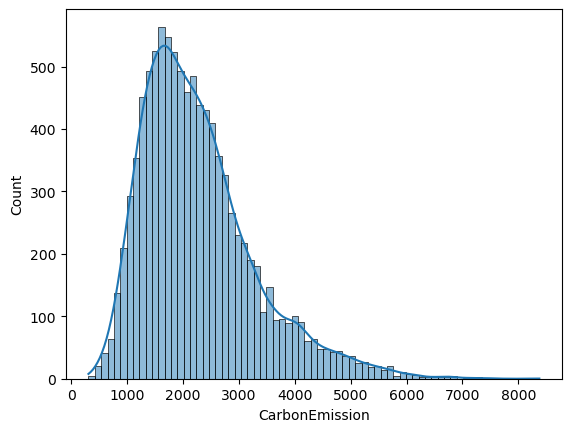

In [19]:
sns.histplot(df['CarbonEmission'], kde=True)
plt.show()

Inference-
- The target is **right-skewed** most people sit around 1,500 to 3,000, and a smaller group has much higher emissions. Linear regression works best when the residuals are roughly symmetric,


In [20]:
cat_cols = df.dtypes[df.dtypes=='object'].index
num_cols = df.dtypes[df.dtypes!='object'].index
print(cat_cols)
print(num_cols)

Index(['Body Type', 'Sex', 'Diet', 'How Often Shower', 'Heating Energy Source',
       'Transport', 'Vehicle Type', 'Social Activity',
       'Frequency of Traveling by Air', 'Waste Bag Size', 'Energy efficiency',
       'Recycling', 'Cooking_With'],
      dtype='object')
Index(['Monthly Grocery Bill', 'Vehicle Monthly Distance Km',
       'Waste Bag Weekly Count', 'How Long TV PC Daily Hour',
       'How Many New Clothes Monthly', 'How Long Internet Daily Hour',
       'CarbonEmission'],
      dtype='object')


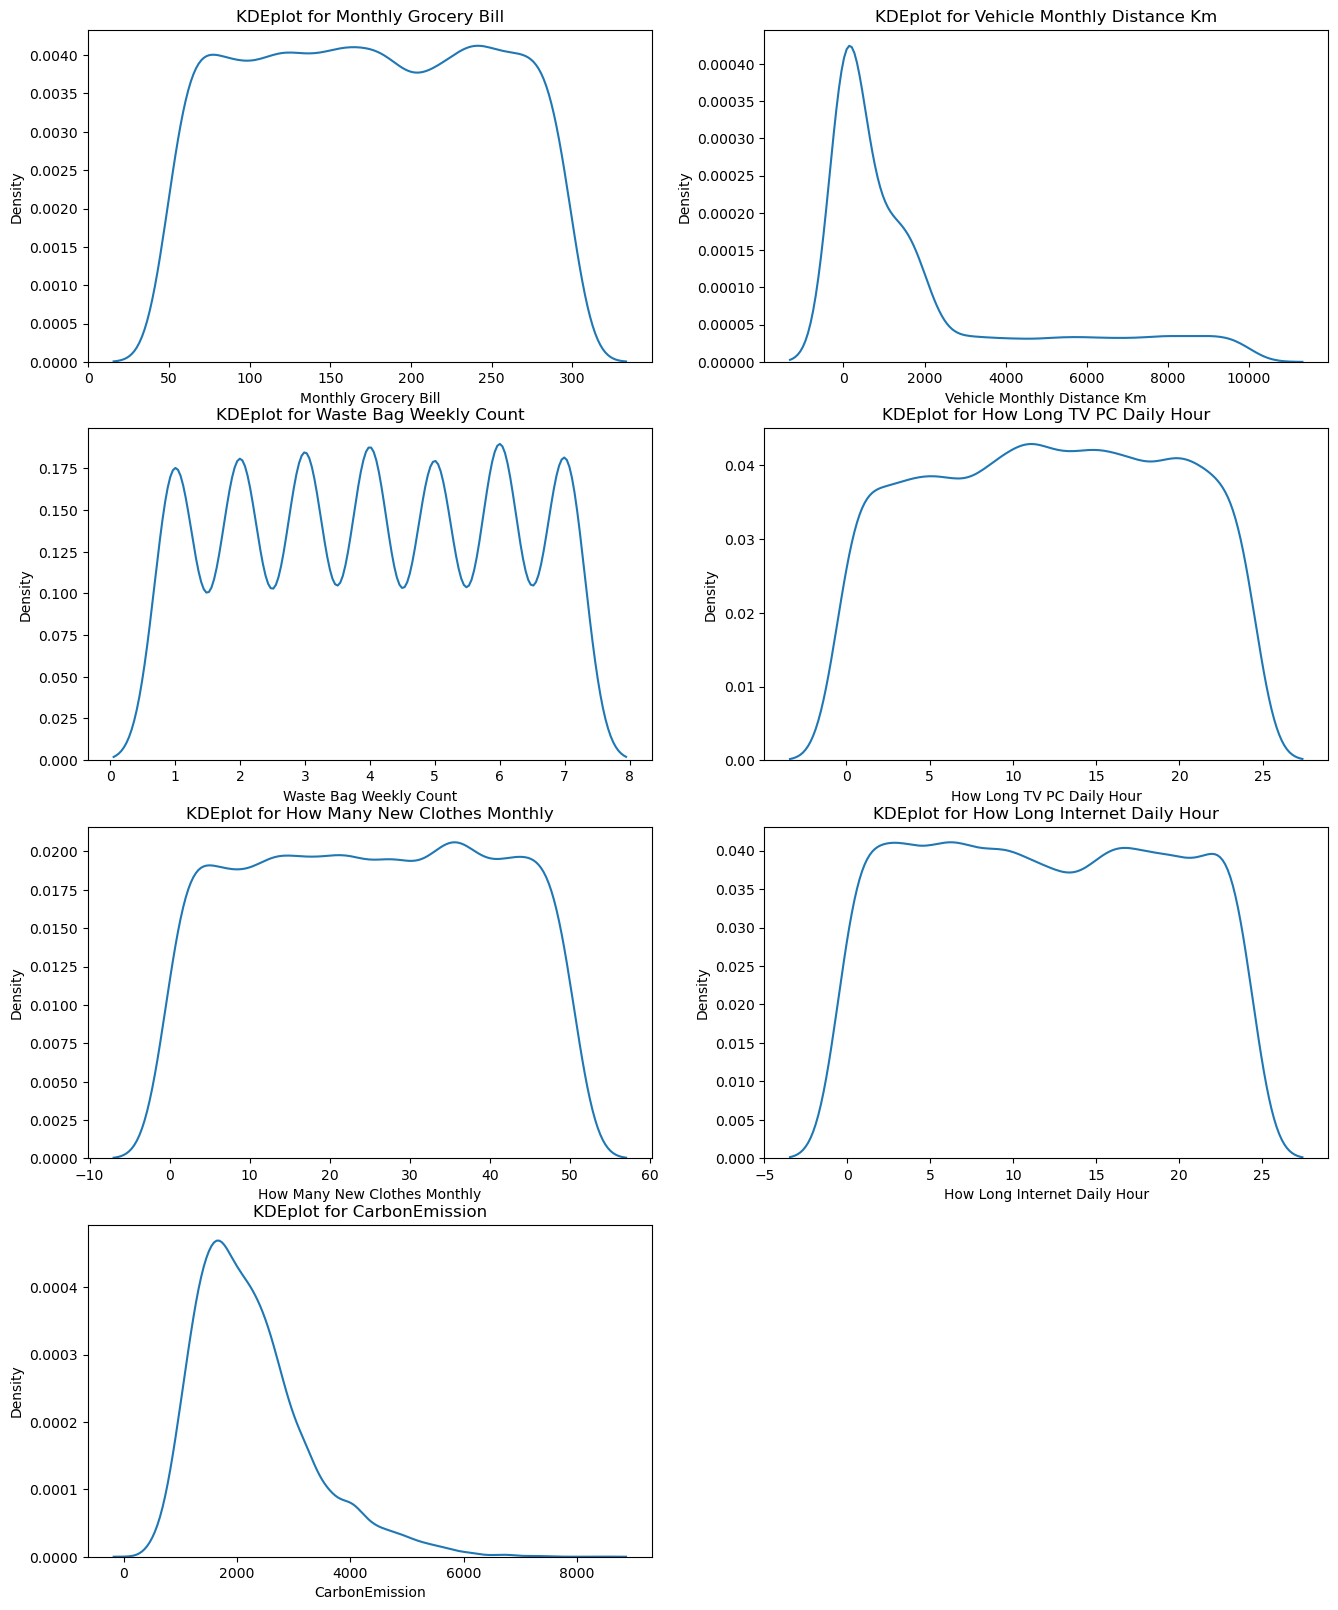

In [21]:
cols = num_cols

plt.figure(figsize=(16,25))
for i in range(len(cols)):
    plt.subplot(5,2,i+1)
    sns.kdeplot(x=df[cols[i]])
    plt.title(f'KDEplot for {cols[i]}')
plt.show()

Inference-
- Grocery bill, TV/PC hours, internet hours, new clothes and waste bag count are roughly flat, which means evenly spread values with no outliers.
- Vehicle distance is heavily right-skewed with a spike near 0 km, and CarbonEmission repeats the right skew.

In [22]:
cat_cols=df.dtypes[df.dtypes=='object'].index
num_cols=df.dtypes[df.dtypes!='object'].index
print(cat_cols)
print(num_cols)

Index(['Body Type', 'Sex', 'Diet', 'How Often Shower', 'Heating Energy Source',
       'Transport', 'Vehicle Type', 'Social Activity',
       'Frequency of Traveling by Air', 'Waste Bag Size', 'Energy efficiency',
       'Recycling', 'Cooking_With'],
      dtype='object')
Index(['Monthly Grocery Bill', 'Vehicle Monthly Distance Km',
       'Waste Bag Weekly Count', 'How Long TV PC Daily Hour',
       'How Many New Clothes Monthly', 'How Long Internet Daily Hour',
       'CarbonEmission'],
      dtype='object')


### Bivariate Analysis
Numeric vs Target variable

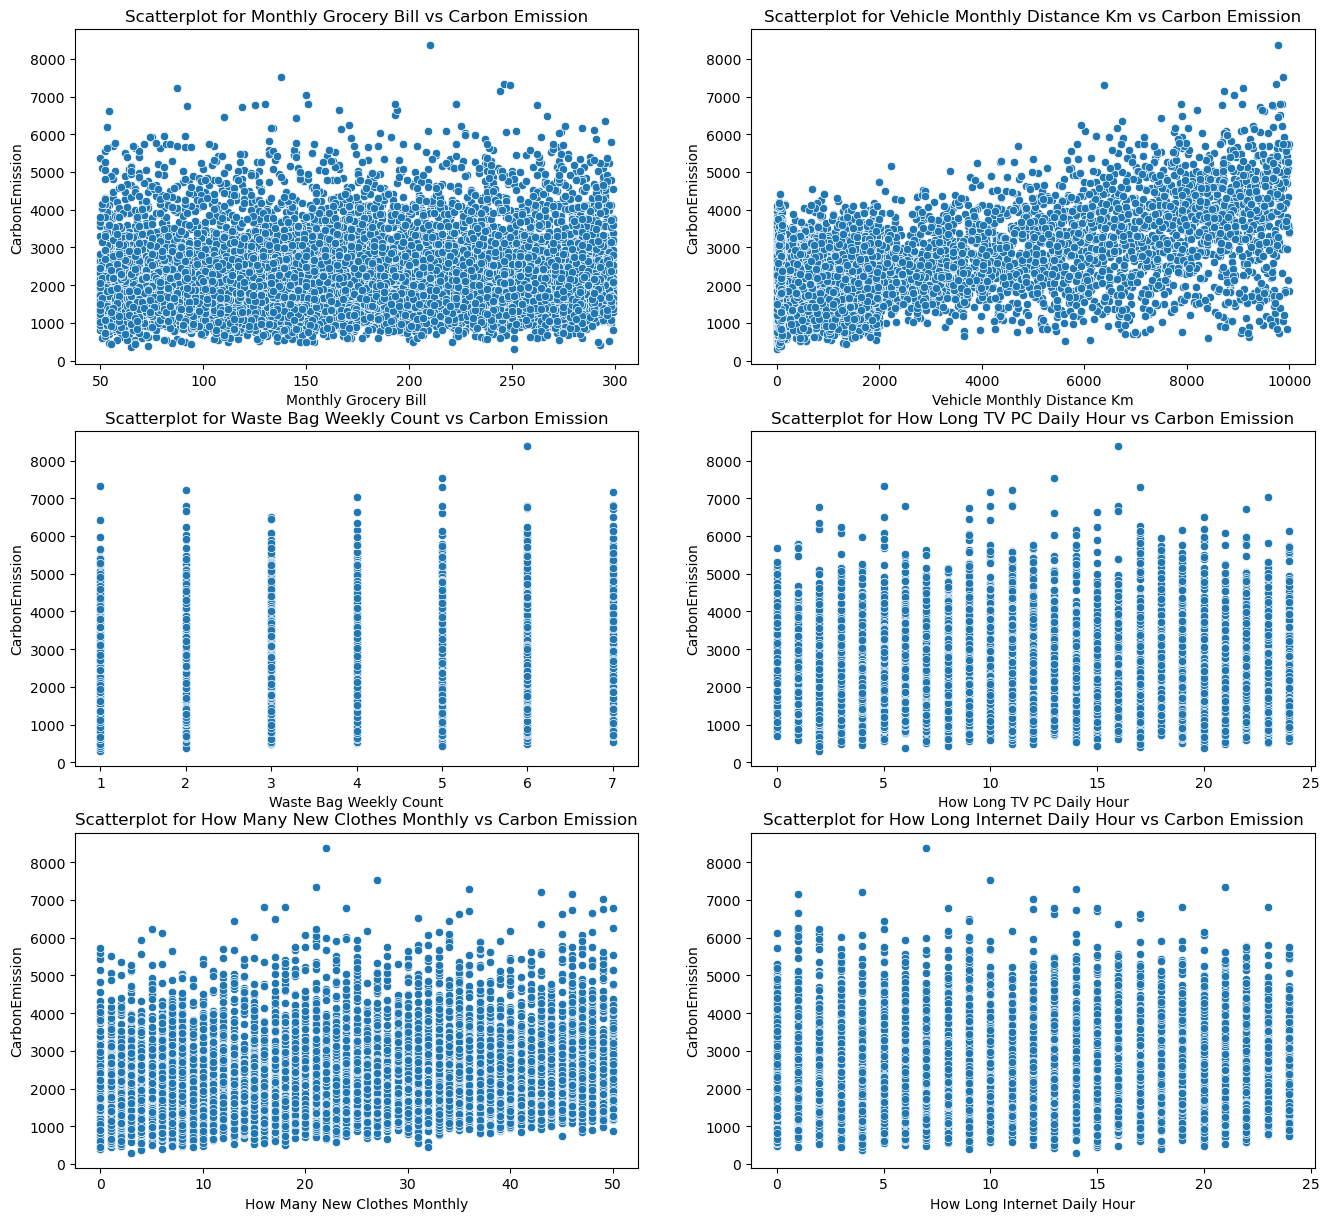

In [23]:
cols = num_cols[:-1]

plt.figure(figsize=(16,20))
for i in range(len(cols)):
    plt.subplot(4,2,i+1)
    sns.scatterplot(x=df[cols[i]],y=df['CarbonEmission'])
    plt.title(f'Scatterplot for {cols[i]} vs Carbon Emission')
plt.show()

Inference-
- Only vehicle distance shows a clear upward trend. New clothes and waste bag count show a mild upward drift, and the rest are flat clouds.

### Correlation

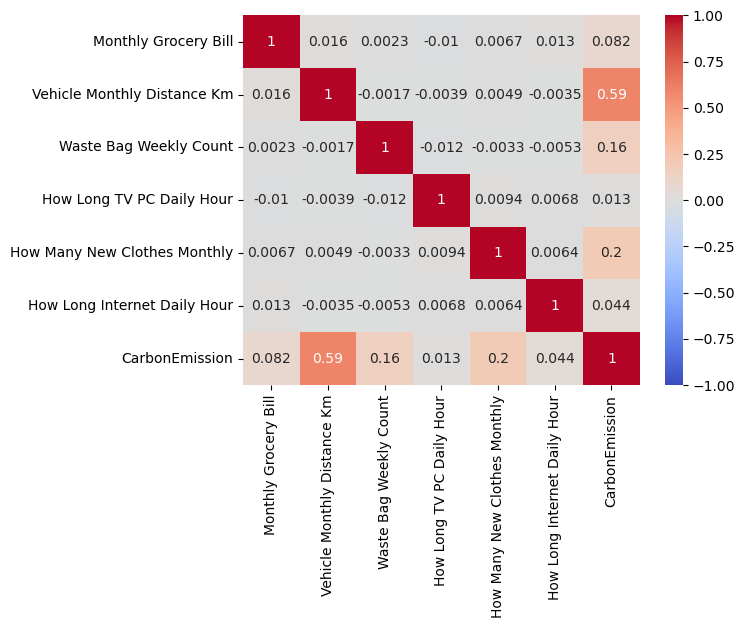

In [24]:
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True,vmin=-1,vmax=1, cmap = 'coolwarm')
plt.show()

Inference-
- Carbon Emission has a moderate positive correlation with Vehicle Monthly Distance Km (0.59) and a weak positive correlation with How Many New Clothes Monthly (0.2), while all other lifestyle variables show almost zero linear relationship with each other or with overall emissions.

### Split the list-type columns (Recycling, Cooking_With) into separate 0/1 columns

In [25]:
df[['Recycling', 'Cooking_With']].head()

,Recycling,Cooking_With
0,['Metal'],"['Stove', 'Oven']"
1,['Metal'],"['Stove', 'Microwave']"
2,['Metal'],"['Oven', 'Microwave']"
3,"['Paper', 'Plastic', 'Glass', 'Metal']","['Microwave', 'Grill', 'Airfryer']"
4,['Paper'],['Oven']


In [26]:
for item in ["Paper", "Plastic", "Glass", "Metal"]:
    df["Recycle_" + item] = df["Recycling"].str.contains(item).astype(int)
for item in ["Stove", "Oven", "Microwave", "Grill", "Airfryer"]:
    df["Cook_" + item] = df["Cooking_With"].str.contains(item).astype(int)
df = df.drop(columns=["Recycling", "Cooking_With"])

In [27]:
df

,Body Type,Sex,Diet,How Often Shower,Heating Energy Source,Transport,Vehicle Type,Social Activity,Monthly Grocery Bill,Frequency of Traveling by Air,...,CarbonEmission,Recycle_Paper,Recycle_Plastic,Recycle_Glass,Recycle_Metal,Cook_Stove,Cook_Oven,Cook_Microwave,Cook_Grill,Cook_Airfryer
0,overweight,female,pescatarian,daily,coal,public,No Vehicle,often,230,frequently,...,2238,0,0,0,1,1,1,0,0,0
1,obese,female,vegetarian,less frequently,natural gas,walk/bicycle,No Vehicle,often,114,rarely,...,1892,0,0,0,1,1,0,1,0,0
2,overweight,male,omnivore,more frequently,wood,private,petrol,never,138,never,...,2595,0,0,0,1,0,1,1,0,0
3,overweight,male,omnivore,twice a day,wood,walk/bicycle,No Vehicle,sometimes,157,rarely,...,1074,1,1,1,1,0,0,1,1,1
4,obese,female,vegetarian,daily,coal,private,diesel,often,266,very frequently,...,4743,1,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,obese,male,omnivore,twice a day,coal,private,hybrid,sometimes,230,never,...,2408,0,0,0,0,0,0,1,0,0
9996,normal,female,vegan,twice a day,coal,private,lpg,never,234,frequently,...,3084,1,1,0,0,1,0,1,0,0
9997,overweight,female,vegetarian,daily,electricity,walk/bicycle,No Vehicle,sometimes,298,very frequently,...,2377,1,1,0,1,0,0,1,1,1
9998,underweight,male,vegan,more frequently,coal,private,petrol,often,179,rarely,...,4574,1,0,0,1,1,0,1,1,1


In [28]:
print(cat_cols)
print(df.shape)

Index(['Body Type', 'Sex', 'Diet', 'How Often Shower', 'Heating Energy Source',
       'Transport', 'Vehicle Type', 'Social Activity',
       'Frequency of Traveling by Air', 'Waste Bag Size', 'Energy efficiency',
       'Recycling', 'Cooking_With'],
      dtype='object')
(10000, 27)


In [29]:
cat_cols

Index(['Body Type', 'Sex', 'Diet', 'How Often Shower', 'Heating Energy Source',
       'Transport', 'Vehicle Type', 'Social Activity',
       'Frequency of Traveling by Air', 'Waste Bag Size', 'Energy efficiency',
       'Recycling', 'Cooking_With'],
      dtype='object')

### Save the cleaned copy

In [30]:
df.to_csv("cleaned_data_carbon.csv",index=False)

In [31]:
cat_cols=df.dtypes[df.dtypes=='object'].index
num_cols=df.dtypes[df.dtypes!='object'].index
print(cat_cols)
print(num_cols)

Index(['Body Type', 'Sex', 'Diet', 'How Often Shower', 'Heating Energy Source',
       'Transport', 'Vehicle Type', 'Social Activity',
       'Frequency of Traveling by Air', 'Waste Bag Size', 'Energy efficiency'],
      dtype='object')
Index(['Monthly Grocery Bill', 'Vehicle Monthly Distance Km',
       'Waste Bag Weekly Count', 'How Long TV PC Daily Hour',
       'How Many New Clothes Monthly', 'How Long Internet Daily Hour',
       'CarbonEmission', 'Recycle_Paper', 'Recycle_Plastic', 'Recycle_Glass',
       'Recycle_Metal', 'Cook_Stove', 'Cook_Oven', 'Cook_Microwave',
       'Cook_Grill', 'Cook_Airfryer'],
      dtype='object')


In [32]:
df_dummies = pd.get_dummies(data=df,columns=cat_cols,drop_first=True,
                           dtype=int)
print(df_dummies.shape)
print(df_dummies.columns)

(10000, 46)
Index(['Monthly Grocery Bill', 'Vehicle Monthly Distance Km',
       'Waste Bag Weekly Count', 'How Long TV PC Daily Hour',
       'How Many New Clothes Monthly', 'How Long Internet Daily Hour',
       'CarbonEmission', 'Recycle_Paper', 'Recycle_Plastic', 'Recycle_Glass',
       'Recycle_Metal', 'Cook_Stove', 'Cook_Oven', 'Cook_Microwave',
       'Cook_Grill', 'Cook_Airfryer', 'Body Type_obese',
       'Body Type_overweight', 'Body Type_underweight', 'Sex_male',
       'Diet_pescatarian', 'Diet_vegan', 'Diet_vegetarian',
       'How Often Shower_less frequently', 'How Often Shower_more frequently',
       'How Often Shower_twice a day', 'Heating Energy Source_electricity',
       'Heating Energy Source_natural gas', 'Heating Energy Source_wood',
       'Transport_public', 'Transport_walk/bicycle', 'Vehicle Type_diesel',
       'Vehicle Type_electric', 'Vehicle Type_hybrid', 'Vehicle Type_lpg',
       'Vehicle Type_petrol', 'Social Activity_often',
       'Social Activity_so

In [33]:
df_dummies.dtypes

Monthly Grocery Bill                             int64
Vehicle Monthly Distance Km                      int64
Waste Bag Weekly Count                           int64
How Long TV PC Daily Hour                        int64
How Many New Clothes Monthly                     int64
How Long Internet Daily Hour                     int64
CarbonEmission                                   int64
Recycle_Paper                                    int64
Recycle_Plastic                                  int64
Recycle_Glass                                    int64
Recycle_Metal                                    int64
Cook_Stove                                       int64
Cook_Oven                                        int64
Cook_Microwave                                   int64
Cook_Grill                                       int64
Cook_Airfryer                                    int64
Body Type_obese                                  int64
Body Type_overweight                             int64
Body Type_

In [34]:
df_dummies.shape

(10000, 46)

### Define features and target

In [35]:
x = df_dummies.drop('CarbonEmission',axis=1)
y = df_dummies['CarbonEmission']
print(x.shape)
print(y.shape)

(10000, 45)
(10000,)


In [36]:
x.head()

,Monthly Grocery Bill,Vehicle Monthly Distance Km,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,Recycle_Paper,Recycle_Plastic,Recycle_Glass,Recycle_Metal,...,Social Activity_often,Social Activity_sometimes,Frequency of Traveling by Air_never,Frequency of Traveling by Air_rarely,Frequency of Traveling by Air_very frequently,Waste Bag Size_large,Waste Bag Size_medium,Waste Bag Size_small,Energy efficiency_Sometimes,Energy efficiency_Yes
0,230,210,4,7,26,1,0,0,0,1,...,1,0,0,0,0,1,0,0,0,0
1,114,9,3,9,38,5,0,0,0,1,...,1,0,0,1,0,0,0,0,0,0
2,138,2472,1,14,47,6,0,0,0,1,...,0,0,1,0,0,0,0,1,1,0
3,157,74,3,20,5,7,1,1,1,1,...,0,1,0,1,0,0,1,0,1,0
4,266,8457,1,3,5,6,1,0,0,0,...,1,0,0,0,1,1,0,0,0,1


In [37]:
y.head()

0    2238
1    1892
2    2595
3    1074
4    4743
Name: CarbonEmission, dtype: int64

## Baseline statistical model (OLS)

### OLS regression summary (statsmodels)

An OLS summary gives:
- Coefficients + p-values (rough statistical significance)
- R² and adjusted R²
- Diagnostics that are useful for assumption checking

In [38]:
import statsmodels.api as sm

In [39]:
x1 = x.copy()   # creating copy of x

In [40]:
y1 = y.copy()   # creating copy of x

In [41]:
x1 = sm.add_constant(x1)
ols_m1 = sm.OLS(y1,x1, missing='drop').fit()
print(ols_m1.summary())

                            OLS Regression Results                            
Dep. Variable:         CarbonEmission   R-squared:                       0.934
Model:                            OLS   Adj. R-squared:                  0.934
Method:                 Least Squares   F-statistic:                     3267.
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:44:22   Log-Likelihood:                -69864.
No. Observations:               10000   AIC:                         1.398e+05
Df Residuals:                    9956   BIC:                         1.401e+05
Df Model:                          43                                         
Covariance Type:            nonrobust                                         
                                                    coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------

#### Compare R2 and Adjusted R2

In [42]:
print("OLS_M1")
print('R2',ols_m1.rsquared)
print('Adj_R2',ols_m1.rsquared_adj)

OLS_M1
R2 0.9338268754648438
Adj_R2 0.9335410735007004


### Splitting data into train & test

In [43]:
from sklearn.model_selection import train_test_split

In [44]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.30,
                                                random_state=57)
print(x_train.shape,x_test.shape)
print(y_train.shape,y_test.shape)

(7000, 45) (3000, 45)
(7000,) (3000,)


## Baseline ML model 
### Importing Model libraries

In [45]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import * 

In [46]:
x_train.head()

,Monthly Grocery Bill,Vehicle Monthly Distance Km,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,Recycle_Paper,Recycle_Plastic,Recycle_Glass,Recycle_Metal,...,Social Activity_often,Social Activity_sometimes,Frequency of Traveling by Air_never,Frequency of Traveling by Air_rarely,Frequency of Traveling by Air_very frequently,Waste Bag Size_large,Waste Bag Size_medium,Waste Bag Size_small,Energy efficiency_Sometimes,Energy efficiency_Yes
428,206,4809,4,13,33,11,1,1,0,0,...,1,0,0,0,1,1,0,0,1,0
4018,129,7355,7,14,15,20,1,0,0,0,...,0,0,0,0,0,0,0,1,0,1
8818,209,1735,1,11,10,18,0,1,1,0,...,1,0,0,0,0,0,0,1,0,1
1744,282,8524,4,18,35,10,0,0,1,0,...,0,0,0,0,1,0,0,1,0,1
5592,185,7955,6,12,13,8,1,1,0,0,...,0,0,0,0,1,0,0,0,0,1


In [47]:
x_test.head()

,Monthly Grocery Bill,Vehicle Monthly Distance Km,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,Recycle_Paper,Recycle_Plastic,Recycle_Glass,Recycle_Metal,...,Social Activity_often,Social Activity_sometimes,Frequency of Traveling by Air_never,Frequency of Traveling by Air_rarely,Frequency of Traveling by Air_very frequently,Waste Bag Size_large,Waste Bag Size_medium,Waste Bag Size_small,Energy efficiency_Sometimes,Energy efficiency_Yes
8404,234,81,2,18,7,14,0,0,0,1,...,0,0,0,1,0,1,0,0,0,1
799,50,4757,3,10,20,3,0,1,1,1,...,0,1,0,1,0,0,0,0,0,1
9703,186,52,2,17,21,15,1,1,0,1,...,1,0,0,0,0,0,1,0,1,0
5960,139,5,3,24,10,5,0,1,1,1,...,0,1,1,0,0,0,1,0,0,1
8729,221,63,1,17,7,16,1,1,1,0,...,0,0,1,0,0,0,1,0,0,1


In [48]:
y_test.head()

8404    1652
799     2272
9703    2016
5960     554
8729     488
Name: CarbonEmission, dtype: int64

In [49]:
def eval_model(ytest,ypred):
    mae= mean_absolute_error(ytest,ypred)
    mse= mean_squared_error(ytest,ypred)
    rmse= np.sqrt(mse)
    r2= r2_score(ytest,ypred)
    print('MAE',mae,'MSE',mse,'RMSE',rmse)
    print('Test_R2',r2)
    

In [50]:
x_train.isna().sum()

Monthly Grocery Bill                             0
Vehicle Monthly Distance Km                      0
Waste Bag Weekly Count                           0
How Long TV PC Daily Hour                        0
How Many New Clothes Monthly                     0
How Long Internet Daily Hour                     0
Recycle_Paper                                    0
Recycle_Plastic                                  0
Recycle_Glass                                    0
Recycle_Metal                                    0
Cook_Stove                                       0
Cook_Oven                                        0
Cook_Microwave                                   0
Cook_Grill                                       0
Cook_Airfryer                                    0
Body Type_obese                                  0
Body Type_overweight                             0
Body Type_underweight                            0
Sex_male                                         0
Diet_pescatarian               

In [51]:
mask = x_train.notna().all(axis=1)
x_train = x_train[mask]
y_train = y_train[mask]   # keep y aligned with x

### Train the baseline Linear Regression model

In [52]:
lr1 = LinearRegression()
lr1.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [53]:
ypred_lr1 = lr1.predict(x_test)  
eval_model(y_test,ypred_lr1)

MAE 169.30600197973305 MSE 65492.89602464364 RMSE 255.91579870075165
Test_R2 0.9334821296988769


In [54]:
print('Train Score',lr1.score(x_train,y_train))   # overfitting check
print('Test Score',lr1.score(x_test,y_test))      

Train Score 0.9337689158095528
Test Score 0.9334821296988769


In [55]:
m_lr = lr1.coef_
c_lr = lr1.intercept_
print('Coef',m_lr)
print('Intercept',c_lr)

Coef [ 9.26470974e-01  2.06844520e-01  8.12363126e+01  2.70810676e+00
  1.35885561e+01  7.12197578e+00 -1.47511344e+02 -5.82186594e+01
 -9.41969500e+01 -1.27574588e+02  2.56698889e+01  3.82626537e+01
  1.65395510e+01  2.20902571e+01  2.20902571e+01  4.29561331e+02
  2.05258320e+02 -1.12244559e+02  3.38845881e+02 -9.08350040e+01
 -1.64174463e+02 -1.35257117e+02 -6.02102111e+00  2.93643356e+01
  2.00451936e+01 -4.24125011e+02 -2.01526253e+02 -1.91873736e+02
 -1.37937800e+02 -7.70258283e+00  2.16462416e+02 -1.04406708e+03
 -2.18726454e+02  3.49437991e+02  8.42533512e+02  1.64856063e+02
  6.70851446e+01 -6.43024184e+02 -4.71781836e+02  6.59850289e+02
 -1.27457482e+02 -2.71892072e+02 -3.79004843e+02 -2.51029355e+01
 -5.93816543e+01]
Intercept 1340.9331377975332


### Regression assumption checks 

In [56]:
 # Pick the top 3 numeric features most correlated with Sales (simple way to choose what to plot)/
numeric_cols = ['Monthly Grocery Bill', 'Vehicle Monthly Distance Km',
       'Waste Bag Weekly Count', 'How Long TV PC Daily Hour',
       'How Many New Clothes Monthly', 'How Long Internet Daily Hour',
       'CarbonEmission']

corr_carbon = df[numeric_cols + ['CarbonEmission']].corr()['CarbonEmission'].drop('CarbonEmission')
corr_carbon

,CarbonEmission,CarbonEmission
Monthly Grocery Bill,0.081587,0.081587
Vehicle Monthly Distance Km,0.594171,0.594171
Waste Bag Weekly Count,0.159193,0.159193
How Long TV PC Daily Hour,0.012985,0.012985
How Many New Clothes Monthly,0.198887,0.198887
How Long Internet Daily Hour,0.043878,0.043878


### 1. Linearity

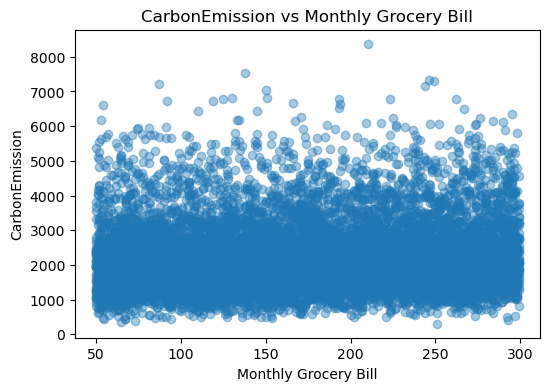

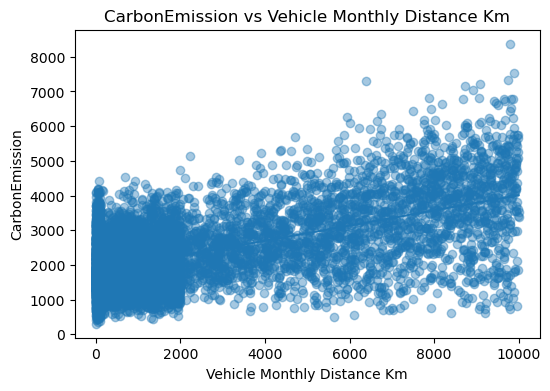

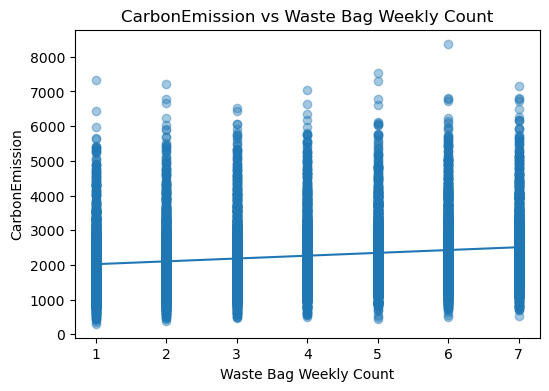

In [57]:
top_features = list(corr_carbon.index[:3])
 
for col in top_features:
    plt.figure(figsize=(6,4))
    plt.scatter(df[col], df['CarbonEmission'], alpha=0.4)
 
    # Simple line of best fit (visual guide)
    m, b = np.polyfit(df[col], df['CarbonEmission'], 1)
    x_line = np.linspace(df[col].min(), df[col].max(), 100)
    plt.plot(x_line, m*x_line + b)
 
    plt.title(f"CarbonEmission vs {col}")
    plt.xlabel(col)
    plt.ylabel("CarbonEmission")
    plt.show()

### 2. Multicollinearity check (VIF)


In [58]:
df

,Body Type,Sex,Diet,How Often Shower,Heating Energy Source,Transport,Vehicle Type,Social Activity,Monthly Grocery Bill,Frequency of Traveling by Air,...,CarbonEmission,Recycle_Paper,Recycle_Plastic,Recycle_Glass,Recycle_Metal,Cook_Stove,Cook_Oven,Cook_Microwave,Cook_Grill,Cook_Airfryer
0,overweight,female,pescatarian,daily,coal,public,No Vehicle,often,230,frequently,...,2238,0,0,0,1,1,1,0,0,0
1,obese,female,vegetarian,less frequently,natural gas,walk/bicycle,No Vehicle,often,114,rarely,...,1892,0,0,0,1,1,0,1,0,0
2,overweight,male,omnivore,more frequently,wood,private,petrol,never,138,never,...,2595,0,0,0,1,0,1,1,0,0
3,overweight,male,omnivore,twice a day,wood,walk/bicycle,No Vehicle,sometimes,157,rarely,...,1074,1,1,1,1,0,0,1,1,1
4,obese,female,vegetarian,daily,coal,private,diesel,often,266,very frequently,...,4743,1,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,obese,male,omnivore,twice a day,coal,private,hybrid,sometimes,230,never,...,2408,0,0,0,0,0,0,1,0,0
9996,normal,female,vegan,twice a day,coal,private,lpg,never,234,frequently,...,3084,1,1,0,0,1,0,1,0,0
9997,overweight,female,vegetarian,daily,electricity,walk/bicycle,No Vehicle,sometimes,298,very frequently,...,2377,1,1,0,1,0,0,1,1,1
9998,underweight,male,vegan,more frequently,coal,private,petrol,often,179,rarely,...,4574,1,0,0,1,1,0,1,1,1


#### VIF after removing the exactly-redundant columns

Three groups of columns are exact copies or exact complements of others, which makes VIF infinite no matter what:

- Cook_Airfryer is identical to Cook_Grill in every row
- Transport_public and Transport_walk/bicycle are fully explained by the Vehicle Type dummies (*No Vehicle* is the baseline)

We drop them **only for this VIF check** (the models above are unchanged) to see whether any real multicollinearity remains.

In [59]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
 
X_vif = x_train.copy()
X_vif_const = sm.add_constant(X_vif)
vif_df = pd.DataFrame()
vif_df['Feature'] = X_vif_const.columns
vif_df['VIF'] = [variance_inflation_factor(X_vif_const.values, i) for i in range(X_vif_const.shape[1])]
 
# Show the top VIF values (higher first)
vif_df.sort_values('VIF', ascending=False).head(15)

,Feature,VIF
14,Cook_Grill,inf
35,Vehicle Type_petrol,inf
30,Transport_walk/bicycle,inf
15,Cook_Airfryer,inf
31,Vehicle Type_diesel,inf
32,Vehicle Type_electric,inf
29,Transport_public,inf
34,Vehicle Type_lpg,inf
33,Vehicle Type_hybrid,inf
2,Vehicle Monthly Distance Km,2.679715


In [60]:
print('Grill == Airfryer in every row:', (x_train['Cook_Grill']==x_train['Cook_Airfryer']).all())

X_vif2 = sm.add_constant(x_train.drop(columns=['Cook_Airfryer','Transport_public','Transport_walk/bicycle']))
vif_df2 = pd.DataFrame()
vif_df2['Feature'] = X_vif2.columns
vif_df2['VIF'] = [variance_inflation_factor(X_vif2.values, i) for i in range(X_vif2.shape[1])]
vif_df2[vif_df2['Feature']!='const'].sort_values('VIF', ascending=False).head(10)

Grill == Airfryer in every row: True


,Feature,VIF
2,Vehicle Monthly Distance Km,2.542183
31,Vehicle Type_lpg,1.536434
19,Diet_pescatarian,1.529761
17,Body Type_underweight,1.523583
40,Waste Bag Size_small,1.521166
15,Body Type_obese,1.520107
38,Waste Bag Size_large,1.518570
20,Diet_vegan,1.517786
21,Diet_vegetarian,1.516275
39,Waste Bag Size_medium,1.515211


### 3. Homoscedasticity check (residuals vs predicted)

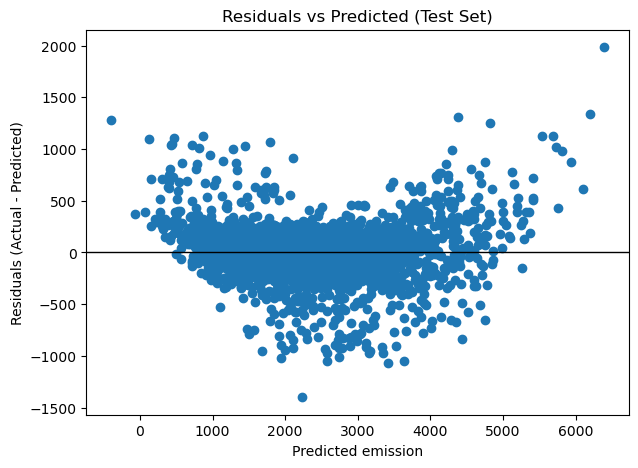

In [61]:
import matplotlib.pyplot as plt

# Predict sales on the test set
ypred_lr1 = lr1.predict(x_test)

# Calculate residuals
residuals = y_test - ypred_lr1

# Plot residuals vs predicted sales
plt.figure(figsize=(7, 5))
plt.scatter(ypred_lr1, residuals)
plt.axhline(0, color='black', linewidth=1)



plt.title('Residuals vs Predicted (Test Set)')
plt.xlabel('Predicted emission')
plt.ylabel('Residuals (Actual - Predicted)')

plt.show()

In [62]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
 
# Fit OLS on training data for diagnostics
X_train_sm = sm.add_constant(x_train)
ols_train = sm.OLS(y_train, X_train_sm).fit()
 
# Breusch–Pagan test
bp_stat, bp_pvalue, f_stat, f_pvalue = het_breuschpagan(ols_train.resid, ols_train.model.exog)
print("Breusch–Pagan p-value:", bp_pvalue)
 
# Durbin–Watson (extra diagnostic)
dw = durbin_watson(ols_train.resid)
print("Durbin–Watson:", dw)
 

Breusch–Pagan p-value: 0.0
Durbin–Watson: 1.9728470979419506


Observation:
- The Breusch-Pagan p-value is essentially 0: there is strong evidence of **heteroscedasticity**.
- The residual table below shows the same thing: the standard deviation of residuals rises from about 176 in the middle deciles to about 402 in the top decile.
- Durbin-Watson is about 1.97, close to 2, so residuals are not autocorrelated (expected, since the rows are not time-ordered).

### 4. Normality of residuals 

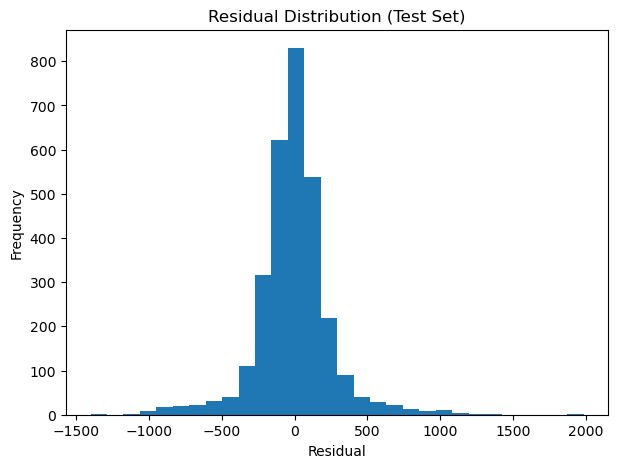

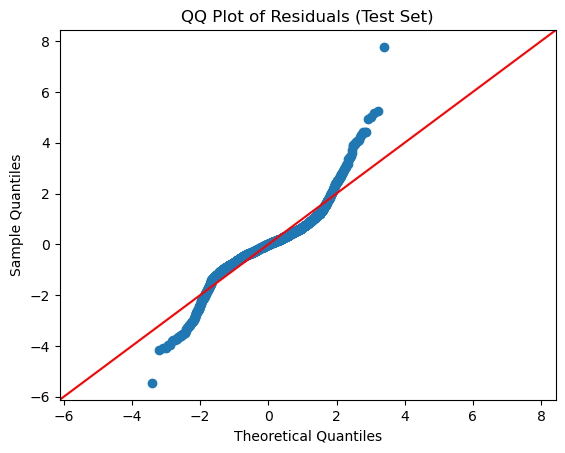

In [63]:
plt.figure(figsize=(7,5))
plt.hist(residuals, bins=30)
plt.title('Residual Distribution (Test Set)')
plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.show()
 
import scipy.stats as stats
sm.qqplot(residuals, line='45', fit=True)
plt.title('QQ Plot of Residuals (Test Set)')
plt.show()

Observation:
- Skewness is about 0.31 and excess kurtosis about 5.6, so the residual tails are heavier than normal and slightly right-skewed. Treat p-values as approximate.
- The decile table confirms your U-shape: the model over-predicts the middle (mean residual about -60 to -90) and under-predicts both ends (about +182 for the lowest and +128 for the highest decile).
- That systematic pattern means the straight-line form is missing something, which Part 3 tests directly.

### Regularized Regression

In [64]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [65]:
# Scale features (fit scaler only on training set)
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
 
# Convert back to DataFrame to keep column names (helps interpretation)
x_train_scaled = pd.DataFrame(x_train_scaled, columns=x_train.columns, index=x_train.index)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=x_test.columns, index=x_test.index)
 

In [66]:
x_train_scaled

,Monthly Grocery Bill,Vehicle Monthly Distance Km,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,Recycle_Paper,Recycle_Plastic,Recycle_Glass,Recycle_Metal,...,Social Activity_often,Social Activity_sometimes,Frequency of Traveling by Air_never,Frequency of Traveling by Air_rarely,Frequency of Traveling by Air_very frequently,Waste Bag Size_large,Waste Bag Size_medium,Waste Bag Size_small,Energy efficiency_Sometimes,Energy efficiency_Yes
428,0.449369,0.990128,-0.009743,0.116927,0.519839,-0.122485,1.008320,1.002575,-0.988919,-0.991748,...,1.413456,-0.697506,-0.569652,-0.575811,1.722210,1.717006,-0.571852,-0.581749,1.387956,-0.704532
4018,-0.616133,1.905265,1.494633,0.257441,-0.699214,1.115529,1.008320,-0.997432,-0.988919,-0.991748,...,-0.707486,-0.697506,-0.569652,-0.575811,-0.580649,-0.582409,-0.571852,1.718954,-0.720484,1.419381
8818,0.490882,-0.114794,-1.514118,-0.164100,-1.037839,0.840415,-0.991748,1.002575,1.011206,-0.991748,...,1.413456,-0.697506,-0.569652,-0.575811,-0.580649,-0.582409,-0.571852,1.718954,-0.720484,1.419381
1744,1.501034,2.325452,-0.009743,0.819494,0.655289,-0.260042,-0.991748,-0.997432,1.011206,-0.991748,...,-0.707486,-0.697506,-0.569652,-0.575811,1.722210,-0.582409,-0.571852,1.718954,-0.720484,1.419381
5592,0.158778,2.120930,0.993174,-0.023586,-0.834664,-0.535156,1.008320,1.002575,-0.988919,-0.991748,...,-0.707486,-0.697506,-0.569652,-0.575811,1.722210,-0.582409,-0.571852,-0.581749,-0.720484,1.419381
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6840,-1.543259,-0.543608,-0.511201,-1.569234,-1.105564,-0.535156,-0.991748,-0.997432,1.011206,1.008320,...,-0.707486,1.433679,-0.569652,-0.575811,1.722210,-0.582409,-0.571852,-0.581749,1.387956,-0.704532
2680,0.518558,-0.287686,0.993174,0.678981,1.400265,-1.498055,1.008320,1.002575,1.011206,1.008320,...,1.413456,-0.697506,-0.569652,-0.575811,-0.580649,-0.582409,-0.571852,-0.581749,-0.720484,-0.704532
3151,0.587746,2.468150,0.491716,1.381548,0.655289,-0.260042,1.008320,1.002575,1.011206,1.008320,...,-0.707486,-0.697506,-0.569652,1.736682,-0.580649,-0.582409,-0.571852,1.718954,-0.720484,-0.704532
3077,-0.851374,-0.216876,-0.009743,-1.007180,-0.089687,1.253086,1.008320,1.002575,-0.988919,1.008320,...,-0.707486,-0.697506,1.755458,-0.575811,-0.580649,-0.582409,-0.571852,1.718954,1.387956,-0.704532



### Train Ridge, Lasso, ElasticNet (no cross-validation yet)

In [67]:
# Helper to store metrics in a clean table
def get_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred)
    }
 
results_initial = []


### Baseline model from Part 1 (already trained): lr1

In [68]:
pred_baseline = lr1.predict(x_test)
baseline_metrics = get_metrics(y_test, pred_baseline)
baseline_metrics['Model'] = 'Baseline LinearRegression (Part 1)'
results_initial.append(baseline_metrics)

### Ridge (L2)

In [69]:
ridge_basic = Ridge(alpha=1.0)
ridge_basic.fit(x_train_scaled, y_train)
pred_ridge = ridge_basic.predict(x_test_scaled)
m_ridge = get_metrics(y_test, pred_ridge)
m_ridge['Model'] = 'Ridge (alpha=1.0)'
results_initial.append(m_ridge)

### Lasso (L1) - alpha is kept small to avoid over-shrinking early

In [70]:
lasso_basic = Lasso(alpha=0.01, max_iter=10000)
lasso_basic.fit(x_train_scaled, y_train)
pred_lasso = lasso_basic.predict(x_test_scaled)
m_lasso = get_metrics(y_test, pred_lasso)
m_lasso['Model'] = 'Lasso (alpha=0.01)'
results_initial.append(m_lasso)

### ElasticNet (L1 + L2)

In [71]:
enet_basic = ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000)
enet_basic.fit(x_train_scaled, y_train)
pred_enet = enet_basic.predict(x_test_scaled)
m_enet = get_metrics(y_test, pred_enet)
m_enet['Model'] = 'ElasticNet (alpha=0.01, l1_ratio=0.5)'
results_initial.append(m_enet)



In [72]:
results_initial_df=pd.DataFrame(results_initial).sort_values('RMSE')
results_initial_df

,MAE,RMSE,R2,Model
3,169.130983,255.802783,0.933541,"ElasticNet (alpha=0.01, l1_ratio=0.5)"
1,169.299920,255.910493,0.933485,Ridge (alpha=1.0)
2,169.304136,255.915356,0.933482,Lasso (alpha=0.01)
0,169.306002,255.915799,0.933482,Baseline LinearRegression (Part 1)


##  K-Fold cross-validation

In [73]:
def kfold_score(model_class, model_params, X, y, k=5, random_state=57):
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    rmse_scores = []
    r2_scores = []

    for tr_idx, val_idx in kf.split(X):
        X_tr = X.iloc[tr_idx]
        X_val = X.iloc[val_idx]
        y_tr = y.iloc[tr_idx]
        y_val = y.iloc[val_idx]

        model = model_class(**model_params)
        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)

        rmse = np.sqrt(mean_squared_error(y_val, pred))
        r2 = r2_score(y_val, pred)

        rmse_scores.append(rmse)
        r2_scores.append(r2)

    return {
        'RMSE_Mean': np.mean(rmse_scores),
        'RMSE_Std': np.std(rmse_scores),
        'R2_Mean': np.mean(r2_scores),
        'R2_Std': np.std(r2_scores)
    }


### Tune Ridge (alpha) with K-Fold

In [74]:
ridge_alphas = [0.01, 0.1, 1, 10, 100, 1000]

ridge_cv_results = []
for a in ridge_alphas:
    res = kfold_score(Ridge, {'alpha': a}, x_train_scaled, y_train)
    res['Model'] = 'Ridge'
    res['alpha'] = a
    ridge_cv_results.append(res)

ridge_cv_df = pd.DataFrame(ridge_cv_results).sort_values('RMSE_Mean')
ridge_cv_df


,RMSE_Mean,RMSE_Std,R2_Mean,R2_Std,Model,alpha
2,266.558265,5.924679,0.932707,0.001892,Ridge,1.00
1,266.558566,5.919469,0.932707,0.001891,Ridge,0.10
0,266.558605,5.918948,0.932707,0.001891,Ridge,0.01
3,266.563698,5.976686,0.932705,0.001904,Ridge,10.00
4,267.380278,6.484874,0.932294,0.002044,Ridge,100.00
5,308.765979,9.962319,0.909722,0.003597,Ridge,1000.00


In [75]:
# print(res)
print(ridge_cv_results)

[{'RMSE_Mean': np.float64(266.5586047929398), 'RMSE_Std': np.float64(5.918947806603608), 'R2_Mean': np.float64(0.9327070295542439), 'R2_Std': np.float64(0.0018908411320305853), 'Model': 'Ridge', 'alpha': 0.01}, {'RMSE_Mean': np.float64(266.5585661508385), 'RMSE_Std': np.float64(5.919468867579991), 'R2_Mean': np.float64(0.9327070513304031), 'R2_Std': np.float64(0.001890961939634277), 'Model': 'Ridge', 'alpha': 0.1}, {'RMSE_Mean': np.float64(266.5582650559914), 'RMSE_Std': np.float64(5.924678614656258), 'R2_Mean': np.float64(0.9327072259703642), 'R2_Std': np.float64(0.0018921721066071395), 'Model': 'Ridge', 'alpha': 1}, {'RMSE_Mean': np.float64(266.56369769669016), 'RMSE_Std': np.float64(5.976686223457008), 'R2_Mean': np.float64(0.9327047052071187), 'R2_Std': np.float64(0.0019044779541957197), 'Model': 'Ridge', 'alpha': 10}, {'RMSE_Mean': np.float64(267.3802778823266), 'RMSE_Std': np.float64(6.484873711940589), 'R2_Mean': np.float64(0.9322936574900517), 'R2_Std': np.float64(0.00204368506

### Tune Lasso (alpha) with K-Fold

In [76]:
lasso_alphas = [0.0001, 0.001, 0.01, 0.1, 1]

lasso_cv_results = []
for a in lasso_alphas:
    res = kfold_score(Lasso, {'alpha': a, 'max_iter': 10000}, x_train_scaled, y_train)
    res['Model'] = 'Lasso'
    res['alpha'] = a
    lasso_cv_results.append(res)

lasso_cv_df = pd.DataFrame(lasso_cv_results).sort_values('RMSE_Mean')
lasso_cv_df

,RMSE_Mean,RMSE_Std,R2_Mean,R2_Std,Model,alpha
0,266.558609,5.918890,0.932707,0.001891,Lasso,0.0001
1,266.558612,5.918895,0.932707,0.001891,Lasso,0.0010
2,266.558646,5.918967,0.932707,0.001891,Lasso,0.0100
3,266.560124,5.919720,0.932706,0.001892,Lasso,0.1000
4,266.683352,5.925645,0.932644,0.001899,Lasso,1.0000


### Tune ElasticNet (alpha and l1_ratio) with K-Fold

In [77]:
enet_alphas = [0.001, 0.01, 0.1, 1, 10]
enet_l1_ratios = [0.1, 0.5, 0.9]

enet_cv_results = []
for a in enet_alphas:
    for l1 in enet_l1_ratios:
        res = kfold_score(ElasticNet, {'alpha': a, 'l1_ratio': l1, 'max_iter': 10000}, x_train_scaled, y_train)
        res['Model'] = 'ElasticNet'
        res['alpha'] = a
        res['l1_ratio'] = l1
        enet_cv_results.append(res)

enet_cv_df = pd.DataFrame(enet_cv_results).sort_values('RMSE_Mean')
enet_cv_df


,RMSE_Mean,RMSE_Std,R2_Mean,R2_Std,Model,alpha,l1_ratio
1,266.558135,5.935096,0.932707,0.001895,ElasticNet,0.001,0.5
2,266.558398,5.922131,0.932707,0.001892,ElasticNet,0.001,0.9
0,266.558817,5.948045,0.932707,0.001898,ElasticNet,0.001,0.1
5,266.559415,5.951322,0.932707,0.001898,ElasticNet,0.010,0.9
4,266.619958,6.080167,0.932677,0.001930,ElasticNet,0.010,0.5
3,266.767810,6.207765,0.932603,0.001964,ElasticNet,0.010,0.1
8,266.841549,6.239237,0.932565,0.001973,ElasticNet,0.100,0.9
7,272.210332,7.411361,0.929828,0.002366,ElasticNet,0.100,0.5
6,281.723874,8.385347,0.924839,0.002778,ElasticNet,0.100,0.1
11,285.854482,8.558411,0.922620,0.002861,ElasticNet,1.000,0.9


### Compare the best configuration from each model

In [78]:
best_ridge = ridge_cv_df.iloc[0]
best_lasso = lasso_cv_df.iloc[0]
best_enet = enet_cv_df.iloc[0]

compare_cv = pd.DataFrame([best_ridge, best_lasso, best_enet])
# print(best_ridge)
# print(best_lasso)
# print(best_enet)
compare_cv[['Model','alpha','l1_ratio','RMSE_Mean','RMSE_Std','R2_Mean','R2_Std']]

,Model,alpha,l1_ratio,RMSE_Mean,RMSE_Std,R2_Mean,R2_Std
2,Ridge,1.0000,NaN,266.558265,5.924679,0.932707,0.001892
0,Lasso,0.0001,NaN,266.558609,5.918890,0.932707,0.001891
1,ElasticNet,0.0010,0.5,266.558135,5.935096,0.932707,0.001895


In [79]:
results_list = []

# Baseline again (for easy comparison in one table)
results_list.append({
    'Model': 'Baseline LinearRegression (Part 1)',
    **get_metrics(y_test, lr1.predict(x_test))
})

# Tuned regularized models (scaled features)
ridge_final = Ridge(alpha=float(best_ridge['alpha']))
lasso_final = Lasso(alpha=float(best_lasso['alpha']), max_iter=10000)
enet_final = ElasticNet(alpha=float(best_enet['alpha']), l1_ratio=float(best_enet['l1_ratio']), max_iter=10000)

for name, model in [('Ridge (tuned)', ridge_final), ('Lasso (tuned)', lasso_final), ('ElasticNet (tuned)', enet_final)]:
    model.fit(x_train_scaled, y_train)
    pred = model.predict(x_test_scaled)
    results_list.append({
        'Model': name,
        **get_metrics(y_test, pred)
    })

results_df = pd.DataFrame(results_list).sort_values('RMSE')
results_df


,Model,MAE,RMSE,R2
3,ElasticNet (tuned),169.284635,255.897753,0.933492
1,Ridge (tuned),169.299920,255.910493,0.933485
2,Lasso (tuned),169.305981,255.915793,0.933482
0,Baseline LinearRegression (Part 1),169.306002,255.915799,0.933482


In [80]:
# Winner based on CV mean RMSE (lower is better)
best_candidates = {
    'Ridge': float(best_ridge['RMSE_Mean']),
    'Lasso': float(best_lasso['RMSE_Mean']),
    'ElasticNet': float(best_enet['RMSE_Mean'])
}
winner = min(best_candidates, key=best_candidates.get)
winner


'ElasticNet'

Observation:
- ElasticNet has the lowest CV RMSE, but the gap between the best and worst of the three models is only about **0.0005**, while the fold-to-fold spread is about 5.9. This is a tie, not a real win.
- Any of Ridge, Lasso or ElasticNet is a fine linear-family choice. The honest conclusion is that regularization did not help here, because plain Linear Regression was not overfitting (train R² 0.9338 vs test R² 0.9335).
- The ceiling comes from the linear form itself, which the next section tests.

# Project Summary

## What we did
1. **Cleaned the data.** 
2. **Prepared the features.** 
3. **Explored the data.** 
4. **Built the models.**


# Conclusion

- A linear model predicts individual carbon emissions well: **test R² ≈ 0.93, MAE ≈ 169, RMSE ≈ 256**. Train and test scores are almost identical, so there is no overfitting.
- Ridge, Lasso and ElasticNet performed the same as plain Linear Regression, so regularization added little. **ElasticNet (alpha = 0.001, l1_ratio = 0.5)** was chosen as the final model because it had the lowest CV error (RMSE ≈ 266.6), although its gap to Ridge and Lasso is only about 0.0005 RMSE against a fold-to-fold spread of about 5.9, so the three are effectively tied.
- **Emissions rise with** frequent flying, petrol or LPG vehicles, more kilometres driven, obese body type, male sex and larger waste output.
- **Emissions fall with** an electric vehicle, never or rarely flying, electric heating, a small waste bag, vegan or vegetarian diets, and recycling (paper, metal, glass and plastic all lower emissions).
- Grocery bill, TV/PC hours and internet hours have almost no effect.
- **Limitations:** the residuals show a U-shape and uneven spread (Breusch-Pagan p ≈ 0), and some columns overlap (Grill/Airfryer, Transport/Vehicle Type), so individual coefficients are approximate. Results show association, not cause and effect.
- **Next steps:** merge the overlapping columns, try a log transform and a distance × vehicle-type interaction, and test tree-based models.


## Limits of the model
- The residuals show a U-shaped pattern and a wider spread for high predictions (Breusch-Pagan p ≈ 0), so the straight-line model underfits some high emitters.
- The residual tails are heavier than normal (QQ plot), so p-values should be treated as approximate.
- Results show association, not proven cause and effect.

## Recommendations
- **For individuals:** the biggest reductions come from switching to an electric vehicle or public transport, flying less, and heating with electricity.
- **For improving the model:** try a log transform of the target, an interaction between distance and commute type, and tree-based models such as Random